# EfficientNet-B0 en Google Colab — PlantVillage

Notebook autocontenido para entrenar un clasificador multiclase con transfer learning usando EfficientNet-B0 preentrenado en ImageNet. Está basado en la línea base de MobileNetV2 del proyecto `LeaftHealthVision`, pero no depende de módulos locales del repositorio.

**Runtime recomendado:** GPU (`Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU`).

> Importante: EfficientNet de Keras ya incorpora el preprocesamiento como una capa `Rescaling`. Por ello, las imágenes se entregan al modelo como tensores float con valores `[0, 255]`; no se aplica `1/255` antes de la base convolucional.


In [1]:
# 0. Dependencias
!pip -q install -U tensorflow matplotlib scikit-learn


In [2]:
# 1. Imports, reproducibilidad y configuración editable
import os
import random
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import applications, layers
from tensorflow.keras.models import Model

SEED = 42
BATCH_SIZE = 32
IMAGE_TARGET_SIZE = (224, 224)
TRAIN_SPLIT = 0.80
VAL_SPLIT = 0.10
TEST_SPLIT = 0.10
EPOCHS = 10
EARLY_STOPPING_PATIENCE = 5
LEARNING_RATE = 1e-3
USE_DATA_AUGMENTATION = True
RUN_FINE_TUNING = False
FINE_TUNE_EPOCHS = 5
FINE_TUNE_LEARNING_RATE = 1e-5
FINE_TUNE_LAST_N_LAYERS = 20

WORK = Path('/content/leafthealthvision')
DATA_DIR = WORK / 'data' / 'plantvillage'
COLOR_DIR = DATA_DIR / 'raw' / 'color'
MODEL_DIR = WORK / 'artifacts'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPO_URL = 'https://github.com/spMohanty/PlantVillage-Dataset.git'

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        tf.keras.mixed_precision.set_global_policy('mixed_float16')
        print(f'GPU activada: {len(gpus)} dispositivo(s), mixed_float16')
    except RuntimeError as exc:
        print(f'Nota GPU: {exc}')
else:
    print('No se detectó GPU; se usará CPU')

print({
    'tensorflow': tf.__version__,
    'device': tf.config.list_logical_devices('GPU'),
    'image_size': IMAGE_TARGET_SIZE,
    'batch_size': BATCH_SIZE,
})


GPU activada: 1 dispositivo(s), mixed_float16
{'tensorflow': '2.21.0', 'device': [LogicalDevice(name='/device:GPU:0', device_type='GPU')], 'image_size': (224, 224), 'batch_size': 32}


In [3]:
# 2. Descargar PlantVillage (solo la primera vez)
if not COLOR_DIR.exists():
    WORK.mkdir(parents=True, exist_ok=True)
    print(f'Clonando {REPO_URL} ...')
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(DATA_DIR)], check=True)
    git_dir = DATA_DIR / '.git'
    if git_dir.exists():
        shutil.rmtree(git_dir)
    keep = {'raw', 'leaf_grouping', 'leaf-map.json', 'README.md', 'CITATION.cff'}
    for item in list(DATA_DIR.iterdir()):
        if item.name not in keep:
            shutil.rmtree(item) if item.is_dir() else item.unlink()
else:
    print(f'Dataset ya descargado en: {DATA_DIR}')

if not COLOR_DIR.exists():
    raise FileNotFoundError(f'No existe el directorio esperado: {COLOR_DIR}')

class_count = len([p for p in COLOR_DIR.iterdir() if p.is_dir()])
print(f'Imágenes en: {COLOR_DIR}')
print(f'Clases encontradas: {class_count}')


Clonando https://github.com/spMohanty/PlantVillage-Dataset.git ...
Imágenes en: /content/leafthealthvision/data/plantvillage/raw/color
Clases encontradas: 38


In [4]:
# 3. Cargar y dividir el dataset
# La división reproduce la línea base del notebook MobileNetV2.
# Para una evaluación académica estricta, se recomienda usar los manifiestos
# por hoja generados por el EDA del repositorio y evitar dividir duplicados
# de una misma hoja entre train/val/test.
AUTOTUNE = tf.data.AUTOTUNE

full_dataset = tf.keras.utils.image_dataset_from_directory(
    COLOR_DIR,
    label_mode='int',
    image_size=IMAGE_TARGET_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)
class_names = full_dataset.class_names
full_dataset = full_dataset.shuffle(
    buffer_size=32, seed=SEED, reshuffle_each_iteration=False
)

n_batches = int(full_dataset.cardinality().numpy())
n_train = int(n_batches * TRAIN_SPLIT)
n_val = int(n_batches * VAL_SPLIT)

train_ds = full_dataset.take(n_train).prefetch(AUTOTUNE)
rest_ds = full_dataset.skip(n_train)
val_ds = rest_ds.take(n_val).prefetch(AUTOTUNE)
test_ds = rest_ds.skip(n_val).prefetch(AUTOTUNE)

print(f'Clases: {len(class_names)}')
print(f'Train batches: {train_ds.cardinality().numpy()}')
print(f'Val batches: {val_ds.cardinality().numpy()}')
print(f'Test batches: {test_ds.cardinality().numpy()}')


Found 54305 files belonging to 38 classes.
Clases: 38
Train batches: 1358
Val batches: 169
Test batches: 171


In [5]:
# 4. Aumentación opcional y modelo EfficientNet-B0
img_height, img_width = IMAGE_TARGET_SIZE
num_classes = len(class_names)

augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name='data_augmentation') if USE_DATA_AUGMENTATION else keras.Sequential([], name='data_augmentation')

# No se agrega layers.Rescaling(1/255): EfficientNetB0 ya normaliza internamente.
base_model = applications.EfficientNetB0(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights='imagenet',
)
base_model.trainable = False

inputs = layers.Input(shape=(img_height, img_width, 3), name='image')
x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
x = layers.Dropout(0.20, name='dropout')(x)
# dtype float32 mantiene estable la salida con mixed_float16.
outputs = layers.Dense(num_classes, dtype='float32', name='classifier')(x)
model = Model(inputs, outputs, name='efficientnetb0_plantvillage')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_plantvillage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [6]:
# 5. Entrenamiento de la cabeza de clasificación
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'efficientnetb0_head.keras', monitor='val_accuracy',
        save_best_only=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7
    ),
]

history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks
)


Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 169s 109ms/step - accuracy: 0.8604 - loss: 0.5996 - val_accuracy: 0.9418 - val_loss: 0.2353 - learning_rate: 0.0010
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 189s 106ms/step - accuracy: 0.9400 - loss: 0.2240 - val_accuracy: 0.9571 - val_loss: 0.1613 - learning_rate: 0.0010
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 144s 105ms/step - accuracy: 0.9515 - loss: 0.1704 - val_accuracy: 0.9630 - val_loss: 0.1375 - learning_rate: 0.0010
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 143s 105ms/step - accuracy: 0.9568 - loss: 0.1474 - val_accuracy: 0.9580 - val_loss: 0.1390 - learning_rate: 0.0010
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 144s 106ms/step - accuracy: 0.9602 - loss: 0.1295 - val_accuracy: 0.9665 - val_loss: 0.1130 - learning_rate: 0.0010
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 202s 105ms/step - accuracy: 0.9615 - loss: 0.1221 - val_accuracy: 0.9639 - val_loss: 0.1149 - learning_rate: 0.0010
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 145s 106ms

In [7]:
# 6. Fine-tuning opcional
# Se ejecuta solo si RUN_FINE_TUNING=True. Mantiene congeladas BatchNorm
# para reducir inestabilidad al ajustar una red preentrenada.
if RUN_FINE_TUNING:
    base_model.trainable = True
    for layer in base_model.layers[:-FINE_TUNE_LAST_N_LAYERS]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    fine_tune_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            MODEL_DIR / 'efficientnetb0_finetuned.keras',
            monitor='val_accuracy', save_best_only=True
        ),
    ]
    fine_tune_history = model.fit(
        train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
        callbacks=fine_tune_callbacks
    )
else:
    print('Fine-tuning omitido: RUN_FINE_TUNING=False')


Fine-tuning omitido: RUN_FINE_TUNING=False


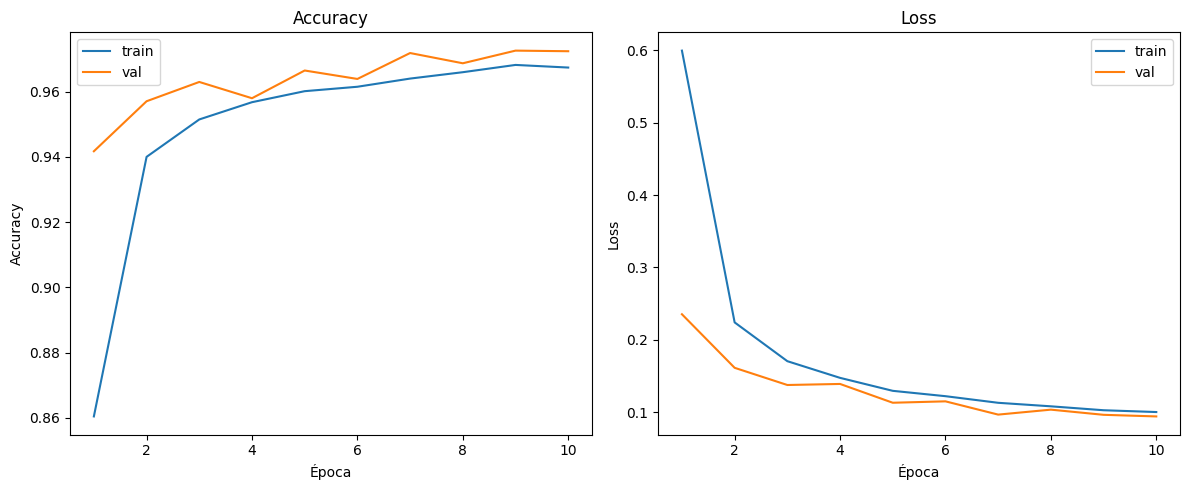

In [8]:
# 7. Curvas de entrenamiento
def plot_history(histories):
    acc, val_acc, loss, val_loss = [], [], [], []
    for hist in histories:
        acc.extend(hist.history.get('accuracy', []))
        val_acc.extend(hist.history.get('val_accuracy', []))
        loss.extend(hist.history.get('loss', []))
        val_loss.extend(hist.history.get('val_loss', []))
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='train')
    plt.plot(epochs_range, val_acc, label='val')
    plt.xlabel('Época'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Accuracy')
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='train')
    plt.plot(epochs_range, val_loss, label='val')
    plt.xlabel('Época'); plt.ylabel('Loss'); plt.legend(); plt.title('Loss')
    plt.tight_layout(); plt.show()

plot_history([history] + ([fine_tune_history] if RUN_FINE_TUNING else []))


In [9]:
# 8. Evaluación final en test y exportación
test_metrics = model.evaluate(test_ds, return_dict=True)
print('Métricas de test:', test_metrics)

final_path = MODEL_DIR / 'efficientnetb0_plantvillage.keras'
model.save(final_path)
np.save(MODEL_DIR / 'class_names.npy', np.array(class_names))
print('Modelo guardado en:', final_path)
print('Clases guardadas en:', MODEL_DIR / 'class_names.npy')


171/171 ━━━━━━━━━━━━━━━━━━━━ 53s 71ms/step - accuracy: 0.9704 - loss: 0.0886
Métricas de test: {'accuracy': 0.9704098701477051, 'loss': 0.08864733576774597}
Modelo guardado en: /content/leafthealthvision/artifacts/efficientnetb0_plantvillage.keras
Clases guardadas en: /content/leafthealthvision/artifacts/class_names.npy


## Notas de reproducibilidad

- La configuración se concentra al inicio del notebook para facilitar experimentos en Colab.
- El split por lotes reproduce la línea base entregada, pero no garantiza separación por hoja física. Para resultados de investigación, usa los manifiestos `data/splits/{train,val,test}.csv` del EDA y documenta el hash de cada split.
- Reporta, además de accuracy, macro-F1, balanced accuracy, recall por clase y matriz de confusión.
- PlantVillage tiene condiciones controladas; la generalización a fotografías de campo requiere un conjunto externo.
